In [1]:
import torch, torchvision
from torch.utils.data import DataLoader
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.__version__)
print(device)

2.13.0+cu126
cuda


In [3]:
total, batch = 60000, 64
print(total // batch)
print(total % batch)
print(937 + 1)

937
32
938


In [5]:
import torch
from torchvision import datasets, transforms
train_all = datasets.MNIST(root="data", train=True, download=True,
                           transform=transforms.ToTensor())

print(len(train_all))
x0, y0 = train_all[0]
print(type(x0).__name__, y0)
print(x0.shape)
print(x0.min().item(), x0.max().item())

100.0%
100.0%
100.0%
100.0%

60000
Tensor 5
torch.Size([1, 28, 28])
0.0 1.0


In [7]:
import torch
from torchvision import datasets, transforms
test = datasets.MNIST(root="data", train=False, download=True,
 transform=transforms.ToTensor()) # 1. 테스트 데이터셋
print(len(test)) # → 10000
x, y = test[100] # 2. 100번 샘플
print(x.shape, y) # → torch.Size([1, 28, 28]) 6
print((test.targets[:1000] == 7).sum().item()) # 3. 라벨 앞 1000개 중 7의 개수
# → 99

10000
torch.Size([1, 28, 28]) 6
99


In [8]:
import torch
from torchvision import datasets, transforms
train_all = datasets.MNIST(root="data", train=True, download=True,
 transform=transforms.ToTensor())
x, y = train_all[59999] # 1. 마지막 샘플 (인덱스는 0부터)
print(x.shape, y) # → torch.Size([1, 28, 28]) 8
raw = datasets.MNIST(root="data", train=True, download=True) # 2. transform 없이 로드
print(type(raw[0][0]).__name__) # → Image (PIL 이미지 원본

torch.Size([1, 28, 28]) 8
Image


In [9]:
import torch
from torchvision import datasets, transforms
train_all = datasets.MNIST(root="data", train=True, download=True,
 transform=transforms.ToTensor())
from torch.utils.data import DataLoader
loader = DataLoader(train_all, batch_size=64, shuffle=True) # 로더 생성 한 줄
print(len(loader)) # → 938 (앞서 계산한 배치 수 그대로)
x, y = next(iter(loader)) # 첫 배치 하나 꺼내 보기 (관용구)
print(x.shape) # → torch.Size([64, 1, 28, 28]) (첫 차원 = 배치 크기)
print(y.shape) # → torch.Size([64]) (라벨도 64개 묶음)
print(y[:8].tolist()) # → ex. [3, 9, 0, 4, 1, 2, 5, 5] (섞여서 매번 다름)

938
torch.Size([64, 1, 28, 28])
torch.Size([64])
[3, 0, 0, 9, 5, 5, 3, 0]


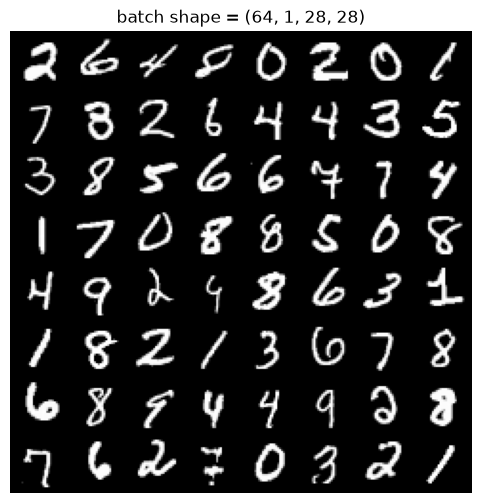

[2, 6, 4, 8, 0, 2, 0, 1]


In [11]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid # 배치를 격자 이미지로 (시각화 유틸)
x, y = next(iter(loader)) # 배치 하나 (샘플 64개)
grid = make_grid(x, nrow=8) # 8개씩 8줄 격자
plt.figure(figsize=(6, 6))
plt.imshow(grid.permute(1, 2, 0)) # (채널, 세로, 가로) → 시각화 순서
plt.title(f"batch shape = {tuple(x.shape)}"); plt.axis("off"); plt.show()
print(y[:8].tolist()) # 첫 줄 8개의 라벨

In [13]:
import torch
from torchvision import datasets, transforms
train_all = datasets.MNIST(root="data", train=True, download=True,
 transform=transforms.ToTensor())
from torch.utils.data import DataLoader
for bs in (16, 256, 8192):
 ld = DataLoader(train_all, batch_size=bs, shuffle=True)
 print(bs, len(ld))
ld = DataLoader(train_all, batch_size=256, shuffle=True)
x, y = next(iter(ld))
print(x.shape)

16 3750
256 235
8192 8
torch.Size([256, 1, 28, 28])


In [14]:
import torch
from torchvision import datasets, transforms
train_all = datasets.MNIST(root="data", train=True, download=True,
 transform=transforms.ToTensor())
from torch.utils.data import DataLoader
ld = DataLoader(train_all, batch_size=100, shuffle=False)
print(len(ld)) # 1. 60000 / 100 = 600배치
# → 600
print(next(iter(ld))[1][:4].tolist()) # 2. shuffle 없이는 저장 순서 그대로
# → [5, 0, 4, 1]

600
[5, 0, 4, 1]


In [15]:
import torch
from torchvision import datasets, transforms
train_all = datasets.MNIST(root="data", train=True, download=True,
 transform=transforms.ToTensor())
from torch.utils.data import DataLoader, random_split
g = torch.Generator().manual_seed(0) # 분리 재현용 시드
train_set, val_set = random_split(train_all, [50000, 10000], generator=g)
print(len(train_set), len(val_set)) # → 50000 10000
train_loader = DataLoader(train_set, batch_size=64, shuffle=True) # 학습 로더, shuffle 켬
val_loader = DataLoader(val_set, batch_size=256, shuffle=False) # 검증 로더, shuffle 끔
print(len(train_loader), len(val_loader)) # → 782 40

50000 10000
782 40


In [ ]:
import torch.nn as nn
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0) # 재현용
model = nn.Sequential(nn.Linear(784, 100), nn.ReLU(),
        nn.Linear(100, 10)).to(device) # 지난주 모델 그대로
opt = torch.optim.SGD(model.parameters(), lr=0.1)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(3): # 3 epoch
 for x, y in train_loader: # 배치 782개 순회
     x, y = x.view(-1, 784).to(device), y.to(device) # 배치를 펴서 GPU로
     loss = loss_fn(model(x), y) # 지난주와 같은 학습 단계
     opt.zero_grad(); loss.backward(); opt.step()
 correct = 0 # epoch 끝마다 검증
 with torch.no_grad():
     for x, y in val_loader:
         x, y = x.view(-1, 784).to(device), y.to(device)
         correct += (model(x).argmax(dim=1) == y).sum().item()
 print(epoch + 1, round(correct / 10000 * 100, 1))
# → (예) 1 89.9
# → (예) 2 93.8
# → (예) 3 94.9 

1 89.9
2 93.8
3 94.9
